In [46]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import xgboost as xgb
import seaborn as sns


from sklearn.metrics import mean_squared_error

import matplotlib.pyplot as plt
plt.style.use('fivethirtyeight')

In [47]:
df=pd.read_csv(r"C:\Users\SOLOMON\Downloads\Telegram Desktop\COVID-19.csv")

In [48]:
df

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2019,continentExp,Cumulative_number_for_14_days_of_COVID-19_cases_per_100000
0,14/12/2020,14,12,2020,746,6,Afghanistan,AF,AFG,38041757.0,Asia,9.013779
1,13/12/2020,13,12,2020,298,9,Afghanistan,AF,AFG,38041757.0,Asia,7.052776
2,12/12/2020,12,12,2020,113,11,Afghanistan,AF,AFG,38041757.0,Asia,6.868768
3,11/12/2020,11,12,2020,63,10,Afghanistan,AF,AFG,38041757.0,Asia,7.134266
4,10/12/2020,10,12,2020,202,16,Afghanistan,AF,AFG,38041757.0,Asia,6.968658
...,...,...,...,...,...,...,...,...,...,...,...,...
61895,25/03/2020,25,3,2020,0,0,Zimbabwe,ZW,ZWE,14645473.0,Africa,NaN
61896,24/03/2020,24,3,2020,0,1,Zimbabwe,ZW,ZWE,14645473.0,Africa,NaN
61897,23/03/2020,23,3,2020,0,0,Zimbabwe,ZW,ZWE,14645473.0,Africa,NaN
61898,22/03/2020,22,3,2020,1,0,Zimbabwe,ZW,ZWE,14645473.0,Africa,NaN


In [49]:
df_africa=df[df["continentExp"]== "Africa"]

In [50]:
df_africa = df_africa.drop(
    columns=[
        "Cumulative_number_for_14_days_of_COVID-19_cases_per_100000",
        "continentExp",
        "popData2019",
        "countryterritoryCode",
        "geoId",
        "countriesAndTerritories",
        "deaths",
        "year",
        "month",
        "day"
    ]
)

In [51]:
df_africa

,dateRep,cases
621,14/12/2020,464
622,13/12/2020,517
623,12/12/2020,542
624,11/12/2020,565
625,10/12/2020,598
...,...,...
61895,25/03/2020,0
61896,24/03/2020,0
61897,23/03/2020,0
61898,22/03/2020,1


In [52]:
df_africa = df_africa.set_index('dateRep')

In [53]:
df_africa.index = pd.to_datetime(df_africa.index, dayfirst=True)

In [54]:
df_africa

,cases
dateRep,
2020-12-14,464
2020-12-13,517
2020-12-12,542
2020-12-11,565
2020-12-10,598
...,...
2020-03-25,0
2020-03-24,0
2020-03-23,0


<Axes: title={'center': 'COVID-19 Africa Cases'}, xlabel='dateRep'>

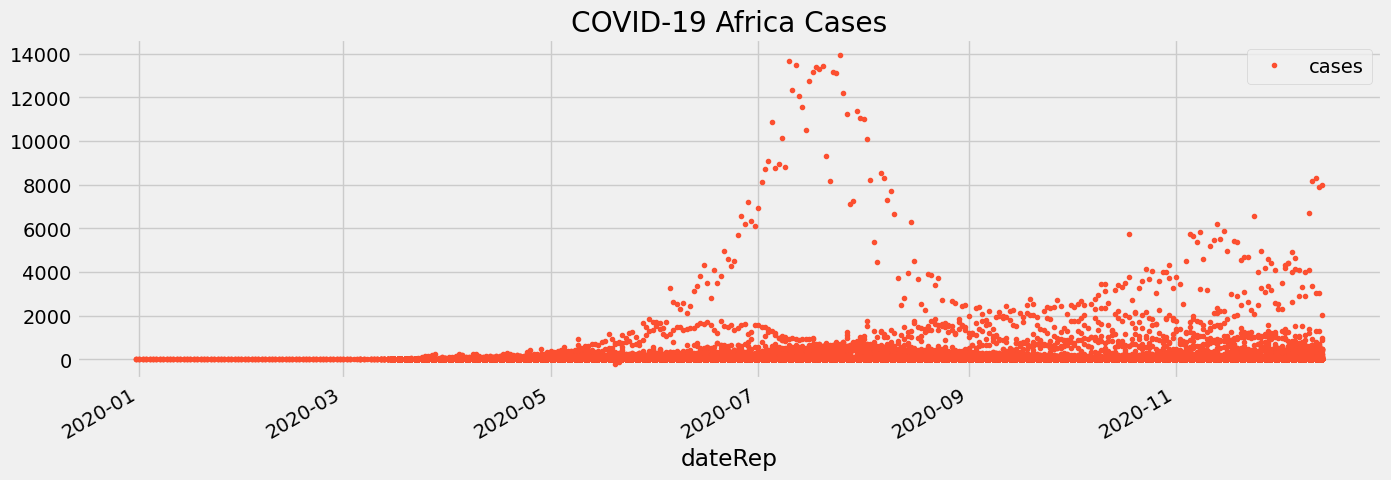

In [57]:
df_africa

color_pallete = sns.color_palette()
df_africa.plot(style='.', figsize=(15,5), color= color_pallete[1], title="COVID-19 Africa Cases")

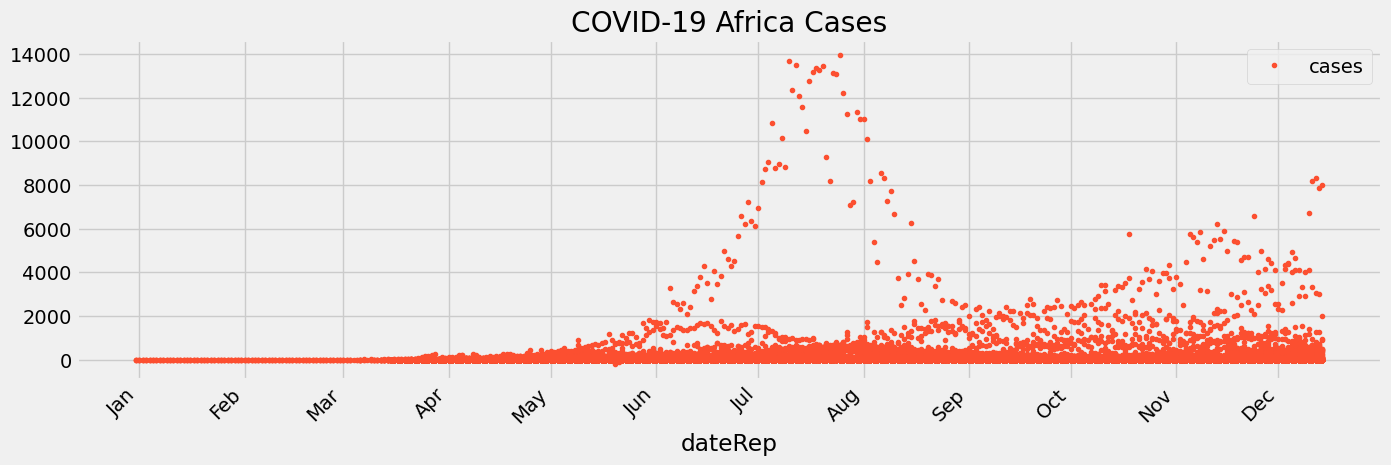

In [59]:
import matplotlib.dates as mdates
color_palette = sns.color_palette()

ax = df_africa.plot(
    style='.',
    figsize=(15,5),
    color=color_palette[1],
    title="COVID-19 Africa Cases"
)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
plt.xticks(rotation=45)
plt.show()
#####
df_africa

#color_pallete = sns.color_palette()
#df_africa.plot(style='.', figsize=(15,5), color= color_pallete[1], title="COVID-19 Africa Cases")

In [60]:
df_africa.index = pd.to_datetime(df_africa.index)

In [61]:
train = df_africa.loc[df_africa.index< '2020-11-30']
test = df_africa.loc[df_africa.index >= '2020-11-30']

In [62]:
len(train), len(test)

(14156, 825)

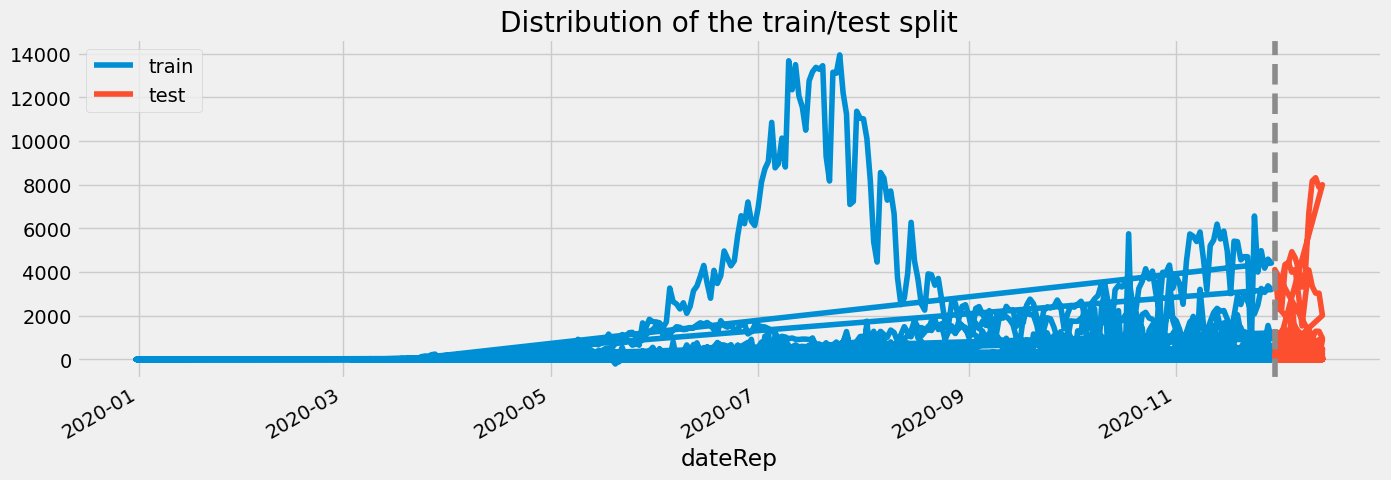

In [63]:
fig, ax = plt.subplots(figsize = (15, 5))
train.plot(ax = ax, label = "Training", title = "Distribution of the train/test split")
test.plot(ax = ax, label = "Testing")
ax.axvline('2020-11-30', color = color_pallete[4], ls = '--')
ax.legend(['train','test'])
plt.show()

In [64]:
def feature_extraction(df_africa):
    df_africa = df_africa.copy()
    
    df_africa['dayofweek'] =df_africa.index.day_of_week
    df_africa['quarter'] = df_africa.index.quarter
    df_africa['month'] = df_africa.index.month
    
    return df_africa 
df_africa = feature_extraction(df_africa)

In [65]:
df_africa

,cases,dayofweek,quarter,month
dateRep,,,,
2020-12-14,464,0,4,12
2020-12-13,517,6,4,12
2020-12-12,542,5,4,12
2020-12-11,565,4,4,12
2020-12-10,598,3,4,12
...,...,...,...,...
2020-03-25,0,2,1,3
2020-03-24,0,1,1,3
2020-03-23,0,0,1,3


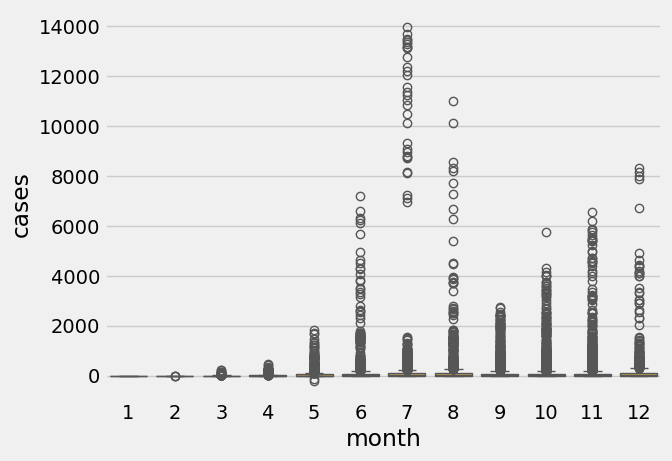

In [17]:
sns.boxplot(data=df_africa, x='month', y = 'cases', color=color_pallete[2])
ax.set_title('Month')
plt.show()

In [66]:
train = feature_extraction(train)
test = feature_extraction(test)


In [67]:
Features  = [ 'dayofweek', 'quarter', 'month']
Target = 'cases'

In [68]:
X_train = train[Features]
Y_train = train[Target]
X_test = test[Features]
Y_test = test[Target]

In [69]:
regression = xgb.XGBRegressor(n_estimators = 200, early_stopping_rounds = True, learning_rate = 0.001)
regression.fit(X_train, Y_train, eval_set = [(X_train, Y_train), (X_test, Y_test)], verbose = True)

[0]	validation_0-rmse:705.69749	validation_1-rmse:885.35080
[1]	validation_0-rmse:705.68570	validation_1-rmse:885.34169
[2]	validation_0-rmse:705.67393	validation_1-rmse:885.33258
[3]	validation_0-rmse:705.66218	validation_1-rmse:885.32349
[4]	validation_0-rmse:705.65046	validation_1-rmse:885.31443
[5]	validation_0-rmse:705.63875	validation_1-rmse:885.30537
[6]	validation_0-rmse:705.62708	validation_1-rmse:885.29634
[7]	validation_0-rmse:705.61541	validation_1-rmse:885.28735
[8]	validation_0-rmse:705.60378	validation_1-rmse:885.27836
[9]	validation_0-rmse:705.59217	validation_1-rmse:885.26939
[10]	validation_0-rmse:705.58060	validation_1-rmse:885.26047
[11]	validation_0-rmse:705.56903	validation_1-rmse:885.25156
[12]	validation_0-rmse:705.55749	validation_1-rmse:885.24266
[13]	validation_0-rmse:705.54596	validation_1-rmse:885.23378
[14]	validation_0-rmse:705.53447	validation_1-rmse:885.22491
[15]	validation_0-rmse:705.52300	validation_1-rmse:885.21609
[16]	validation_0-rmse:705.51156	v

,objective,'reg:squarederror'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,True
,enable_categorical,True
,eval_metric,None


In [70]:
regression.feature_importances_

array([0.01863339, 0.12210275, 0.8592639 ], dtype=float32)

In [71]:
feature_stat = pd.DataFrame(data = regression.feature_importances_, 
             index= regression.feature_names_in_,
            columns = ['importance'])

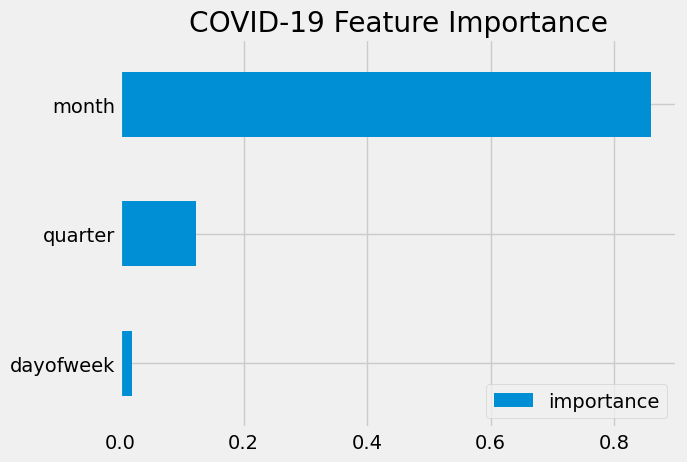

In [72]:
feature_stat.sort_values('importance').plot(kind = 'barh', title = 'COVID-19 Feature Importance')
plt.show()

In [73]:
test['Prediction'] = regression.predict(X_test)

In [74]:
test

,cases,dayofweek,quarter,month,Prediction
dateRep,,,,,
2020-12-14,464,0,4,12,142.075195
2020-12-13,517,6,4,12,171.020035
2020-12-12,542,5,4,12,171.020035
2020-12-11,565,4,4,12,171.020035
2020-12-10,598,3,4,12,171.020035
...,...,...,...,...,...
2020-12-04,181,4,4,12,171.020035
2020-12-03,114,3,4,12,171.020035
2020-12-02,95,2,4,12,165.984863


In [75]:
test.shape

(825, 5)

In [76]:
df_africa = df_africa.merge(test[['Prediction']], how='left', left_index=True, right_index=True)

In [42]:
monthly_df = df_africa.resample('M').sum()      # or .mean()

C:\Users\SOLOMON\AppData\Local\Temp\ipykernel_33948\625082534.py:1: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  monthly_df = df_africa.resample('M').sum()      # or .mean()


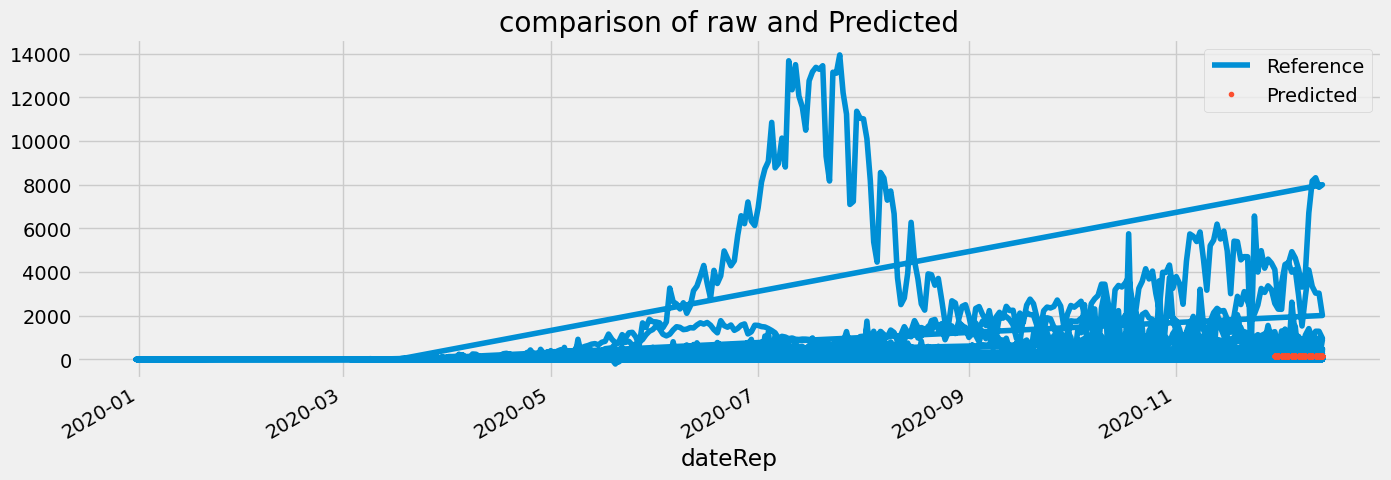

In [77]:
ax = df_africa[['cases']].plot(figsize=(15,5))
df_africa['Prediction'].plot(ax = ax,  style = '.')
plt.legend(["Reference", "Predicted"])
ax.set_title('comparison of raw and Predicted')
plt.show()

In [78]:
mse_score = np.sqrt(mean_squared_error(test['cases'], test['Prediction']))

In [79]:
print(f'Mean Square Error (RMSE) on the test data is {mse_score:0.4}')

Mean Square Error (RMSE) on the test data is 883.6


In [ ]:
##################################################

In [85]:
df_africa

,dateRep,day,month,year,cases,deaths,countriesAndTerritories,geoId,countryterritoryCode,popData2019,continentExp,Cumulative_number_for_14_days_of_COVID-19_cases_per_100000
17498,2019-12-31,31,12,2019,0,0,Egypt,EG,EGY,100388076.0,Africa,NaN
42016,2019-12-31,31,12,2019,0,0,Nigeria,NG,NGA,200963603.0,Africa,NaN
965,2019-12-31,31,12,2019,0,0,Algeria,DZ,DZA,43053054.0,Africa,NaN
42015,2020-01-01,1,1,2020,0,0,Nigeria,NG,NGA,200963603.0,Africa,NaN
964,2020-01-01,1,1,2020,0,0,Algeria,DZ,DZA,43053054.0,Africa,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...
51838,2020-12-14,14,12,2020,7999,170,South_Africa,ZA,ZAF,58558267.0,Africa,125.109577
41409,2020-12-14,14,12,2020,59,0,Niger,NE,NER,23310719.0,Africa,3.183085
34677,2020-12-14,14,12,2020,0,0,Madagascar,MG,MDG,26969306.0,Africa,1.101252
24752,2020-12-14,14,12,2020,0,0,Guinea_Bissau,GW,GNB,1920917.0,Africa,1.145286


In [87]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import Ridge,LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from statsmodels.tsa.arima.model import ARIMA

sns.set_theme(style="whitegrid")

# ---------------------------------------------------------
# 1. Prepare & Aggregate Time Series Data
# ---------------------------------------------------------
# Filter for Africa (ECDC dataset column format)
df_africa = df[df["continentExp"] == "Africa"].copy()

# Ensure date column is datetime and sorted chronologically
# Adjust 'dateRep' or 'date' to your actual date column name
date_col = "dateRep" 
target_col = "cases"  # e.g., 'cases', 'deaths', or 'value'

df_africa[date_col] = pd.to_datetime(df_africa[date_col], dayfirst=True)
df_africa = df_africa.sort_values(by=date_col)

# Aggregate daily total for the continent (or filter by a single country)
ts_data = df_africa.groupby(date_col)[target_col].sum().reset_index()
ts_data.set_index(date_col, inplace=True)
ts_data = ts_data.asfreq("D").fillna(0)  # Ensure daily frequency

# ---------------------------------------------------------
# 2. Feature Engineering for ML Models (Lag & Rolling Features)
# ---------------------------------------------------------
df_ml = ts_data.copy()

# Create lag features (past days values)
for lag in [1, 2, 3, 7, 14, 30]:
    df_ml[f"lag_{lag}"] = df_ml[target_col].shift(lag)

# Create rolling window statistics
df_ml["rolling_mean_7"] = df_ml[target_col].shift(1).rolling(7).mean()
df_ml["rolling_std_7"] = df_ml[target_col].shift(1).rolling(7).std()

# Drop rows with NaN from lagging
df_ml.dropna(inplace=True)

# ---------------------------------------------------------
# 3. Time-Based Train/Test Split (Sequential Split)
# ---------------------------------------------------------
# Do NOT use random train_test_split for time series data
test_days = 60  # Hold out the last 60 days for testing

X = df_ml.drop(columns=[target_col])
y = df_ml[target_col]

X_train, X_test = X.iloc[:-test_days], X.iloc[-test_days:]
y_train, y_test = y.iloc[:-test_days], y.iloc[-test_days:]

# ---------------------------------------------------------
# 4. Train & Predict with Multiple Algorithms
# ---------------------------------------------------------
predictions = {}
results = []

# --- Model A: Machine Learning Regressors ---
ml_models = {
    "LinearRegression":LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

for name, model in ml_models.items():
    model.fit(X_train, y_train)
    preds = model.predict(X_test)
    predictions[name] = pd.Series(preds, index=y_test.index)
    
    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)
    results.append({"Model": name, "MAE": mae, "RMSE": rmse, "R2 Score": r2})

# --- Model B: Statistical Time-Series Model (ARIMA) ---
try:
    arima_model = ARIMA(y_train, order=(7, 1, 1)).fit()
    arima_preds = arima_model.forecast(steps=test_days)
    predictions["ARIMA(7,1,1)"] = arima_preds
    
    mae = mean_absolute_error(y_test, arima_preds)
    rmse = np.sqrt(mean_squared_error(y_test, arima_preds))
    r2 = r2_score(y_test, arima_preds)
    results.append({"Model": "ARIMA(7,1,1)", "MAE": mae, "RMSE": rmse, "R2 Score": r2})
except Exception as e:
    print(f"ARIMA fitting skipped due to: {e}")

# Save metrics summary
results_df = pd.DataFrame(results).sort_values(by="RMSE")
print("=== Time Series Model Comparison ===")
print(results_df.to_string(index=False))

C:\Users\SOLOMON\anaconda3\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


=== Time Series Model Comparison ===
            Model         MAE        RMSE  R2 Score
 Ridge Regression 1670.208930 2090.932821  0.483202
 LinearRegression 1670.208934 2090.932827  0.483202
     ARIMA(7,1,1) 1986.389781 2449.189629  0.290936
Gradient Boosting 2086.161680 2558.548813  0.226202
    Random Forest 2187.341000 2635.804080  0.178767


In [88]:
ts_data

,cases
dateRep,
2019-12-31,0
2020-01-01,0
2020-01-02,0
2020-01-03,0
2020-01-04,0
...,...
2020-12-10,18892
2020-12-11,19111
2020-12-12,18909


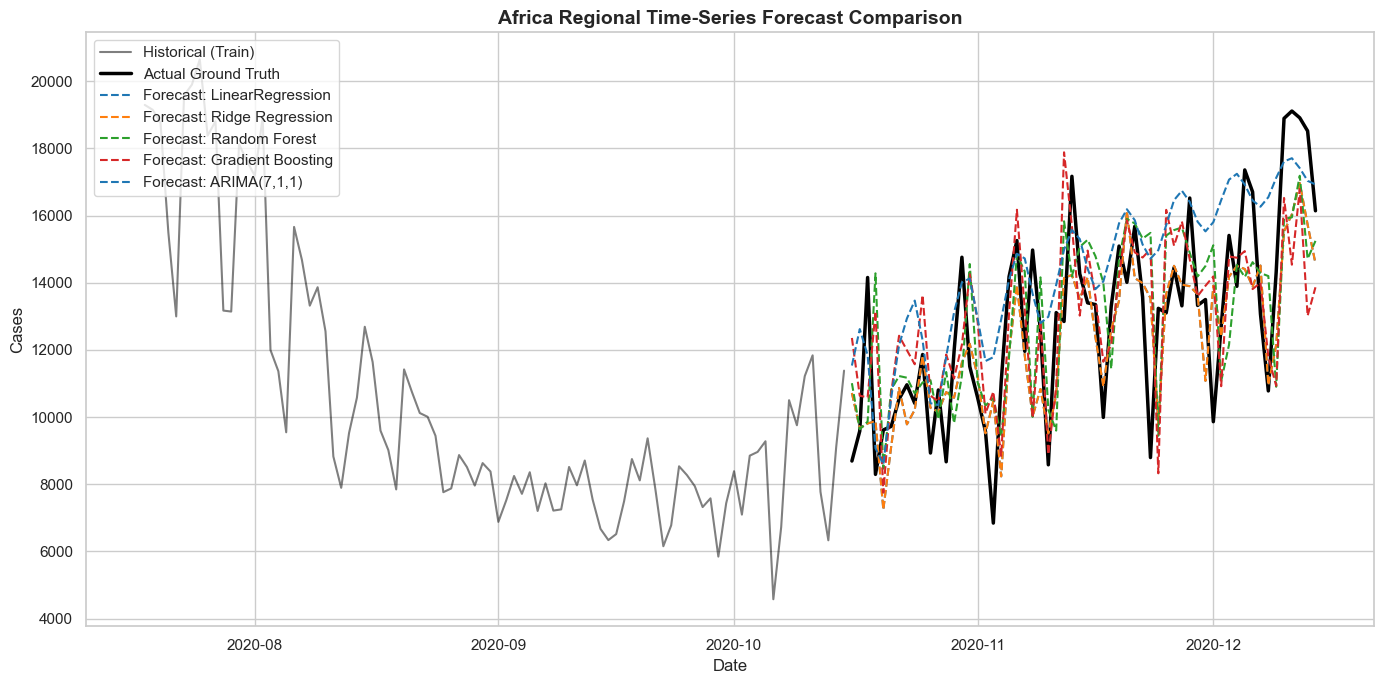

In [92]:
plt.figure(figsize=(14, 7))

# Plot actual historical values
plt.plot(y_train.index[-90:], y_train.values[-90:], label="Historical (Train)", color="black", alpha=0.5)
plt.plot(y_test.index, y_test.values, label="Actual Ground Truth", color="black", linewidth=2.5)

# Plot forecasts from each model
colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728"]
for i, (name, pred_series) in enumerate(predictions.items()):
    plt.plot(pred_series.index, pred_series.values, label=f"Forecast: {name}", linestyle="--", color=colors[i % len(colors)])

plt.title("Africa Regional Time-Series Forecast Comparison", fontsize=14, fontweight="bold")
plt.xlabel("Date")
plt.ylabel(target_col.capitalize())
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()